# Section 7: Modern Transformers and Mixture of Experts

**Student:** WuShangxuan  
**GitHub username:** WuShangxuan0106  
**Date:** 2026-10-12

This notebook continues the Section 6 polymer-gap task. It compares a compact
modern dense Transformer with a top-2 Mixture-of-Experts (MoE) version. The
same train/validation/test split is used so that architecture and routing are
the main experimental changes.

## 0. Reproducibility and evaluation contract

The notebook runs on CPU. Random seeds are fixed, preprocessing is fitted only
on the training split, validation selects the checkpoint, and the test split is
used once for the final comparison.

In [1]:
from __future__ import annotations

from copy import deepcopy
import gc
from pathlib import Path
import math
import random
import time

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

GLOBAL_SEED = 42
SPLIT_SEED = 42
TARGET = "HOMO_LUMO_Gap_eV"
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
DEVICE = torch.device("cpu")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

def set_seed(seed: int = GLOBAL_SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

def regression_metrics(y_true, y_pred) -> dict[str, float]:
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": float(r2_score(y_true, y_pred)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mse),
        "RMSE": float(np.sqrt(mse)),
    }

PROCESS = psutil.Process()

def current_rss_mb() -> float:
    return PROCESS.memory_info().rss / (1024 ** 2)

set_seed(GLOBAL_SEED)
print("numpy", np.__version__)
print("torch", torch.__version__)
print("device", DEVICE)

numpy 2.5.2
torch 2.13.0
device cpu


## 1. Data and token audit

Rows with `Energy_Hatree == 0` are treated as failed calculations. The input is
the polymer PSMILES string and the target is the HOMO-LUMO gap in eV. This is a
regression task, so the final comparison reports R2, MAE, MSE, and RMSE.

In [2]:
def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "sections").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root")

REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / "sections/s02/homework/openpoly_calculated_properties.csv"
raw_df = pd.read_csv(DATA_PATH)
valid_mask = (
    raw_df["Energy_Hatree"].ne(0.0)
    & raw_df["psmiles"].notna()
    & raw_df[TARGET].notna()
)
df = raw_df.loc[valid_mask].reset_index(drop=True).copy()
df["sequence_length"] = df["psmiles"].astype(str).str.len()

print("raw rows:", len(raw_df))
print("removed failed calculations:", int((raw_df["Energy_Hatree"] == 0).sum()))
print("valid modeling rows:", len(df))
print("target unit: eV")
print("unique PSMILES:", df["psmiles"].nunique())
print("\nTarget summary:")
print(df[TARGET].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(4).to_string())
print("\nSequence-length summary:")
print(df["sequence_length"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_string())

q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
outlier_mask = (df[TARGET] < q1 - 1.5 * iqr) | (df[TARGET] > q3 + 1.5 * iqr)
print("\nTarget IQR outliers:", int(outlier_mask.sum()))
print(df.loc[outlier_mask, ["id", "Name", "sequence_length", TARGET]].to_string(index=False))

raw rows: 1000
removed failed calculations: 74
valid modeling rows: 926
target unit: eV
unique PSMILES: 926

Target summary:
count    926.0000
mean       8.3081
std        0.4814
min        4.4689
25%        8.0222
50%        8.3395
75%        8.6126
95%        8.9850
99%        9.6735
max       10.0010

Sequence-length summary:
count    926.00
mean      53.49
std        9.17
min       35.00
25%       47.00
50%       52.00
75%       58.00
95%       71.75
99%       80.75
max       98.00

Target IQR outliers: 26
 id               Name  sequence_length  HOMO_LUMO_Gap_eV
  3 OMG_polymer_105232               37           10.0010
160 OMG_polymer_168059               55            9.7729
199  OMG_polymer_97237               50            9.8756
236 OMG_polymer_192331               55            9.6632
298 OMG_polymer_150234               47            9.8169
300 OMG_polymer_148088               57            6.5123
395 OMG_polymer_164834               53            9.6770
439 OMG_polymer_2026

/var/folders/7c/jdc732g90mq3htnp6mq_k1rc0000gn/T/ipykernel_49385/3058082527.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df[TARGET], vert=True, patch_artist=True, boxprops={"facecolor": "#dd8452"})


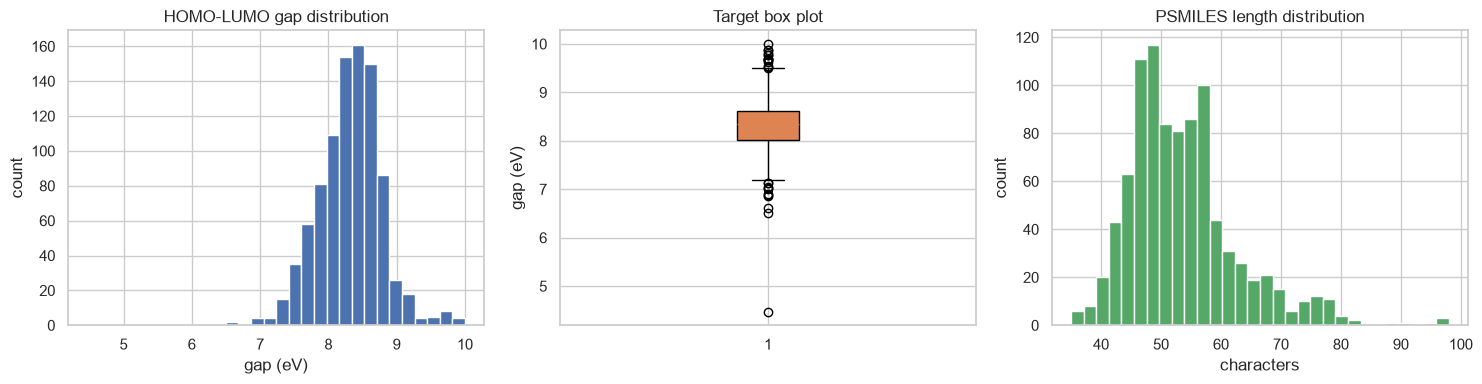

Largest absolute numeric Pearson correlations with the target:
HOMO_eV                                          -0.6450
LUMO_eV                                           0.6436
Isotropic_Polarizability_au                      -0.2283
es                                               -0.1307
Thermal_correction_to_Gibbs_Free_Energy_Hatree    0.0784
Dipole_Debye                                     -0.0522
Entropy_Hatree                                    0.0337
Gibbs_Free_Energy_Hatree                          0.0134
Energy_Hatree                                     0.0134
Enthalpy_Hatree                                   0.0134
Inner_energy_correction_Hatree                   -0.0001
Thermal_correction_to_Enthalpy_Hatree                NaN

Leakage note: HOMO_eV and LUMO_eV are excluded from all sequence models.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df[TARGET], bins=30, color="#4c72b0", edgecolor="white")
axes[0].set(title="HOMO-LUMO gap distribution", xlabel="gap (eV)", ylabel="count")
axes[1].boxplot(df[TARGET], vert=True, patch_artist=True, boxprops={"facecolor": "#dd8452"})
axes[1].set(title="Target box plot", ylabel="gap (eV)")
axes[2].hist(df["sequence_length"], bins=30, color="#55a868", edgecolor="white")
axes[2].set(title="PSMILES length distribution", xlabel="characters", ylabel="count")
plt.tight_layout()
plt.show()

numeric_candidates = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in {"id", TARGET, "sequence_length"}
]
numeric_corr = (
    df[numeric_candidates + [TARGET]]
    .corr(method="pearson")[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print("Largest absolute numeric Pearson correlations with the target:")
print(numeric_corr.head(12).round(4).to_string())
print("\nLeakage note: HOMO_eV and LUMO_eV are excluded from all sequence models.")

### Fixed cumulative split and character vocabulary

The split is 60/20/20. The vocabulary, maximum token length, and target scaler
are fitted on training rows only. Validation is used for model selection.

In [4]:
indices = np.arange(len(df))
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SPLIT_SEED,
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.25,
    random_state=SPLIT_SEED,
)

def assert_disjoint(*index_arrays) -> None:
    sets = [set(map(int, idx)) for idx in index_arrays]
    for i in range(len(sets)):
        for j in range(i + 1, len(sets)):
            assert sets[i].isdisjoint(sets[j]), f"Split {i} and split {j} overlap"

assert_disjoint(train_idx, val_idx, test_idx)
print("split sizes:", len(train_idx), len(val_idx), len(test_idx))
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    values = df.loc[idx, TARGET]
    print(f"{name:10s} mean={values.mean():.4f} std={values.std(ddof=1):.4f} min={values.min():.4f} max={values.max():.4f}")

train_sequences = df.loc[train_idx, "psmiles"].astype(str).tolist()
train_lengths = np.array([len(s) for s in train_sequences], dtype=int)
MAX_LEN = int(np.percentile(train_lengths, 99))

vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for ch in sorted(set("".join(train_sequences))):
    if ch not in vocab:
        vocab[ch] = len(vocab)
inv_vocab = {idx: token for token, idx in vocab.items()}
PAD_IDX = vocab[PAD_TOKEN]
UNK_IDX = vocab[UNK_TOKEN]

def encode_sequence(text: str, max_len: int = MAX_LEN) -> np.ndarray:
    ids = [vocab.get(ch, UNK_IDX) for ch in str(text)[:max_len]]
    ids = ids + [PAD_IDX] * (max_len - len(ids))
    return np.asarray(ids, dtype=np.int64)

def encode_many(texts) -> np.ndarray:
    return np.stack([encode_sequence(s) for s in texts])

X_train = encode_many(df.loc[train_idx, "psmiles"])
X_val = encode_many(df.loc[val_idx, "psmiles"])
X_test = encode_many(df.loc[test_idx, "psmiles"])

y_train_raw = df.loc[train_idx, TARGET].to_numpy(np.float32)
y_val_raw = df.loc[val_idx, TARGET].to_numpy(np.float32)
y_test_raw = df.loc[test_idx, TARGET].to_numpy(np.float32)
y_scaler = StandardScaler().fit(y_train_raw.reshape(-1, 1))
y_train = y_scaler.transform(y_train_raw.reshape(-1, 1)).ravel().astype(np.float32)
y_val = y_scaler.transform(y_val_raw.reshape(-1, 1)).ravel().astype(np.float32)
y_test = y_scaler.transform(y_test_raw.reshape(-1, 1)).ravel().astype(np.float32)

print("vocabulary size:", len(vocab))
print("chosen MAX_LEN:", MAX_LEN)
print("encoded train shape:", X_train.shape)
print("target scaler mean/std:", float(y_scaler.mean_[0]), float(np.sqrt(y_scaler.var_[0])))

token_counts = X_train.astype(bool).sum(axis=1)
print("\nTraining token-count summary:")
print(pd.Series(token_counts).describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_string())
char_counts = pd.Series(list("".join(train_sequences))).value_counts()
print("\nMost common training characters:")
print(char_counts.head(15).to_string())

split sizes: 555 185 186
train      mean=8.3051 std=0.4697 min=6.5123 max=9.8756
validation mean=8.3139 std=0.4748 min=6.8784 max=10.0010
test       mean=8.3116 std=0.5230 min=4.4689 max=9.6941
vocabulary size: 30
chosen MAX_LEN: 78
encoded train shape: (555, 78)
target scaler mean/std: 8.305065784798012 0.46928486444529227

Training token-count summary:
count    555.00
mean      53.36
std        8.74
min       35.00
25%       47.00
50%       52.00
75%       58.00
95%       72.30
99%       78.00
max       78.00

Most common training characters:
c    6261
(    4183
)    4183
C    3930
O    2812
=    2103
N    1462
1    1432
*    1110
2     716
F     273
S     214
n     197
3     154
B     147


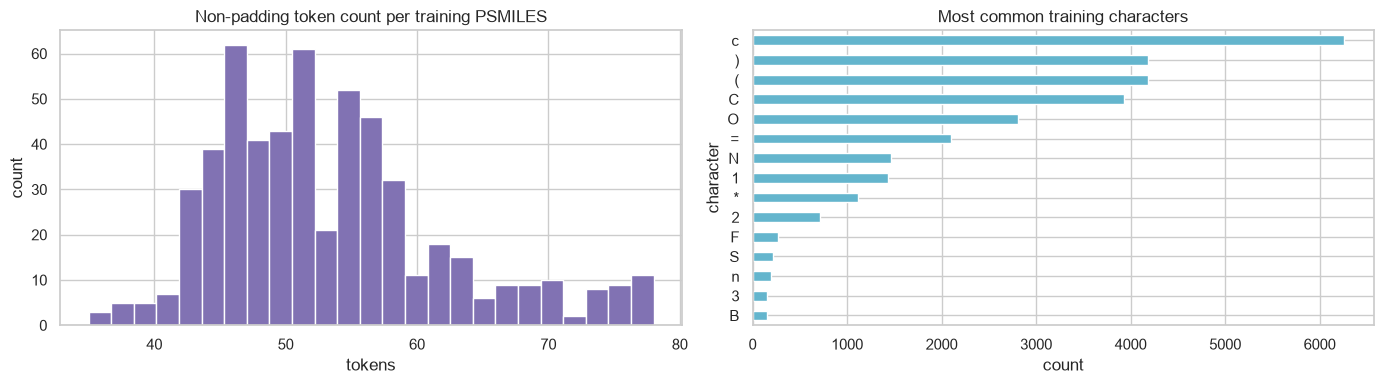

/var/folders/7c/jdc732g90mq3htnp6mq_k1rc0000gn/T/ipykernel_49385/2046691998.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=length_by_split, x="split", y="sequence_length", ax=ax, palette="Set2")


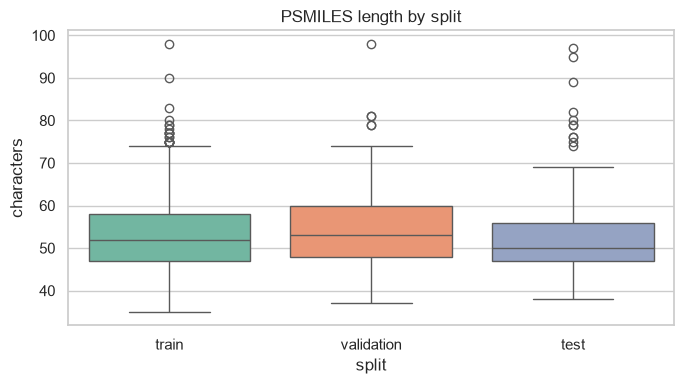

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(token_counts, bins=25, color="#8172b3", edgecolor="white")
axes[0].set(title="Non-padding token count per training PSMILES", xlabel="tokens", ylabel="count")
char_counts.head(15).sort_values().plot(kind="barh", ax=axes[1], color="#64b5cd")
axes[1].set(title="Most common training characters", xlabel="count", ylabel="character")
plt.tight_layout()
plt.show()

length_by_split = pd.DataFrame({
    "split": np.concatenate([
        np.repeat("train", len(train_idx)),
        np.repeat("validation", len(val_idx)),
        np.repeat("test", len(test_idx)),
    ]),
    "sequence_length": np.concatenate([
        df.loc[train_idx, "sequence_length"],
        df.loc[val_idx, "sequence_length"],
        df.loc[test_idx, "sequence_length"],
    ]),
})
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=length_by_split, x="split", y="sequence_length", ax=ax, palette="Set2")
ax.set(title="PSMILES length by split", ylabel="characters")
plt.tight_layout()
plt.show()

## 2. Architecture diagrams

The modern dense block uses pre-normalization, RMSNorm, rotary positional
embeddings (RoPE), multi-head self-attention, and a gated SwiGLU feed-forward
network. The MoE block keeps the same attention path but replaces the dense
feed-forward network with several expert feed-forward networks selected by a
small learned router.

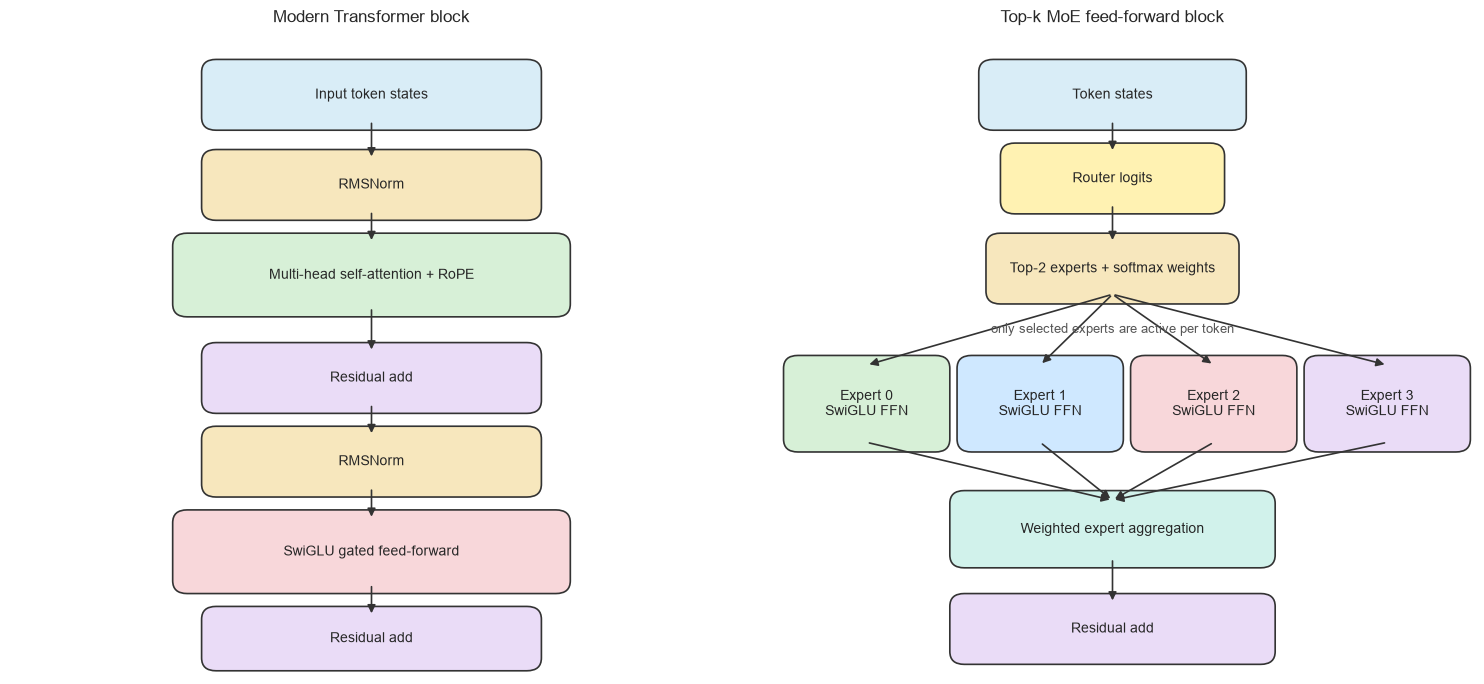

In [6]:
def draw_box(ax, xy, width, height, text, facecolor, edgecolor="#333333"):
    box = FancyBboxPatch(
        xy,
        width,
        height,
        boxstyle="round,pad=0.015,rounding_size=0.02",
        linewidth=1.2,
        edgecolor=edgecolor,
        facecolor=facecolor,
    )
    ax.add_patch(box)
    ax.text(xy[0] + width / 2, xy[1] + height / 2, text, ha="center", va="center", fontsize=10)

def draw_arrow(ax, start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=12, linewidth=1.2, color="#333333"))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

ax = axes[0]
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Modern Transformer block")
draw_box(ax, (0.28, 0.86), 0.44, 0.08, "Input token states", "#d9edf7")
draw_box(ax, (0.28, 0.72), 0.44, 0.08, "RMSNorm", "#f7e7bd")
draw_box(ax, (0.24, 0.57), 0.52, 0.10, "Multi-head self-attention + RoPE", "#d7f0d7")
draw_box(ax, (0.28, 0.42), 0.44, 0.08, "Residual add", "#eadcf7")
draw_box(ax, (0.28, 0.29), 0.44, 0.08, "RMSNorm", "#f7e7bd")
draw_box(ax, (0.24, 0.14), 0.52, 0.10, "SwiGLU gated feed-forward", "#f8d7da")
draw_box(ax, (0.28, 0.02), 0.44, 0.07, "Residual add", "#eadcf7")
for start, end in [
    ((0.5, 0.86), (0.5, 0.80)),
    ((0.5, 0.72), (0.5, 0.67)),
    ((0.5, 0.57), (0.5, 0.50)),
    ((0.5, 0.42), (0.5, 0.37)),
    ((0.5, 0.29), (0.5, 0.24)),
    ((0.5, 0.14), (0.5, 0.09)),
]:
    draw_arrow(ax, start, end)

ax = axes[1]
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("Top-k MoE feed-forward block")
draw_box(ax, (0.33, 0.86), 0.34, 0.08, "Token states", "#d9edf7")
draw_box(ax, (0.36, 0.73), 0.28, 0.08, "Router logits", "#fff2b2")
draw_box(ax, (0.34, 0.59), 0.32, 0.08, "Top-2 experts + softmax weights", "#f7e7bd")
expert_colors = ["#d7f0d7", "#cfe8ff", "#f8d7da", "#eadcf7"]
for i, color in enumerate(expert_colors):
    draw_box(ax, (0.06 + i * 0.24, 0.36), 0.20, 0.12, f"Expert {i}\nSwiGLU FFN", color)
draw_box(ax, (0.29, 0.18), 0.42, 0.09, "Weighted expert aggregation", "#d1f2eb")
draw_box(ax, (0.29, 0.03), 0.42, 0.08, "Residual add", "#eadcf7")
draw_arrow(ax, (0.5, 0.86), (0.5, 0.81))
draw_arrow(ax, (0.5, 0.73), (0.5, 0.67))
for i in range(4):
    draw_arrow(ax, (0.5, 0.59), (0.16 + i * 0.24, 0.48))
for i in range(4):
    draw_arrow(ax, (0.16 + i * 0.24, 0.36), (0.5, 0.27))
draw_arrow(ax, (0.5, 0.18), (0.5, 0.11))
ax.text(0.5, 0.53, "only selected experts are active per token", ha="center", fontsize=9, color="#555555")

plt.tight_layout()
plt.show()

## 3. Modern dense and MoE model implementation

The router predicts one score per expert. For each token, the top two experts
are selected and their gate weights are normalized. During training, a
load-balancing auxiliary loss discourages the router from sending almost all
tokens to one expert.

In [7]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        return self.weight * x * torch.rsqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)


class SwiGLU(nn.Module):
    def __init__(self, d_model: int, hidden_dim: int, dropout: float):
        super().__init__()
        self.gate = nn.Linear(d_model, hidden_dim)
        self.value = nn.Linear(d_model, hidden_dim)
        self.out = nn.Linear(hidden_dim, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.out(F.silu(self.gate(x)) * self.value(x)))


class TopKMoE(nn.Module):
    def __init__(
        self,
        d_model: int,
        hidden_dim: int,
        n_experts: int,
        top_k: int,
        dropout: float,
    ):
        super().__init__()
        if top_k < 1 or top_k > n_experts:
            raise ValueError("top_k must be between 1 and n_experts")
        self.n_experts = n_experts
        self.top_k = top_k
        self.router = nn.Linear(d_model, n_experts)
        self.experts = nn.ModuleList([
            SwiGLU(d_model, hidden_dim, dropout) for _ in range(n_experts)
        ])

    def forward(self, x, collect_stats: bool = False):
        batch, tokens, d_model = x.shape
        flat = x.reshape(batch * tokens, d_model)
        router_logits = self.router(flat)
        router_probs = torch.softmax(router_logits, dim=-1)
        top_probs, top_indices = router_probs.topk(self.top_k, dim=-1)
        gate_weights = top_probs / top_probs.sum(dim=-1, keepdim=True).clamp_min(1e-9)

        output = torch.zeros_like(flat)
        assignment_counts = torch.zeros(self.n_experts, device=x.device)
        for expert_id, expert in enumerate(self.experts):
            selected = top_indices.eq(expert_id)
            token_weight = (gate_weights * selected.to(gate_weights.dtype)).sum(dim=-1)
            if selected.any():
                output = output + token_weight.unsqueeze(-1) * expert(flat)
            assignment_counts[expert_id] = selected.sum()

        assignment_fraction = assignment_counts / assignment_counts.sum().clamp_min(1.0)
        importance = router_probs.mean(dim=0)
        load_balance_loss = self.n_experts * torch.sum(importance * assignment_fraction)
        stats = None
        if collect_stats:
            stats = {
                "router_prob_sum": router_probs.detach().sum(dim=0).cpu().numpy(),
                "assignment_counts": assignment_counts.detach().cpu().numpy(),
                "token_count": float(len(flat)),
                "load_balance_loss": float(load_balance_loss.detach().cpu()),
            }
        return output.view(batch, tokens, d_model), load_balance_loss, stats


def rope_rotate(x, positions: torch.Tensor) -> torch.Tensor:
    dim = x.shape[-1]
    if dim % 2 != 0:
        raise ValueError("RoPE requires an even head dimension")
    inv_freq = 1.0 / (10_000 ** (torch.arange(0, dim, 2, device=x.device).float() / dim))
    angles = positions.float().unsqueeze(-1) * inv_freq.unsqueeze(0)
    cos = torch.cat([angles.cos(), angles.cos()], dim=-1).unsqueeze(0).unsqueeze(0)
    sin = torch.cat([angles.sin(), angles.sin()], dim=-1).unsqueeze(0).unsqueeze(0)
    x_even = x[..., : dim // 2]
    x_odd = x[..., dim // 2 :]
    rotated = torch.cat([-x_odd, x_even], dim=-1)
    return x * cos + rotated * sin


class ModernSelfAttention(nn.Module):
    def __init__(self, d_model: int, nhead: int, dropout: float):
        super().__init__()
        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead")
        self.d_model = d_model
        self.nhead = nhead
        self.head_dim = d_model // nhead
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None, need_weights=False):
        batch, tokens, _ = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q = q.view(batch, tokens, self.nhead, self.head_dim).transpose(1, 2)
        k = k.view(batch, tokens, self.nhead, self.head_dim).transpose(1, 2)
        v = v.view(batch, tokens, self.nhead, self.head_dim).transpose(1, 2)
        positions = torch.arange(tokens, device=x.device)
        q = rope_rotate(q, positions)
        k = rope_rotate(k, positions)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        if key_padding_mask is not None:
            scores = scores.masked_fill(key_padding_mask[:, None, None, :], -1e9)
        weights = torch.softmax(scores, dim=-1)
        attended = torch.matmul(weights, v)
        attended = attended.transpose(1, 2).contiguous().view(batch, tokens, self.d_model)
        return self.out_proj(self.dropout(attended)), weights if need_weights else None


class ModernTransformerBlock(nn.Module):
    def __init__(
        self,
        d_model: int,
        nhead: int,
        dim_feedforward: int,
        dropout: float,
        use_moe: bool,
        n_experts: int,
        top_k: int,
    ):
        super().__init__()
        self.norm1 = RMSNorm(d_model)
        self.attention = ModernSelfAttention(d_model, nhead, dropout)
        self.dropout1 = nn.Dropout(dropout)
        self.norm2 = RMSNorm(d_model)
        self.use_moe = use_moe
        if use_moe:
            self.feed_forward = TopKMoE(d_model, dim_feedforward, n_experts, top_k, dropout)
        else:
            self.feed_forward = SwiGLU(d_model, dim_feedforward, dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, key_padding_mask=None, return_attention=False, collect_router_stats=False):
        attended, weights = self.attention(
            self.norm1(x),
            key_padding_mask=key_padding_mask,
            need_weights=return_attention,
        )
        x = x + self.dropout1(attended)
        if self.use_moe:
            ff_output, aux_loss, router_stats = self.feed_forward(
                self.norm2(x),
                collect_stats=collect_router_stats,
            )
        else:
            ff_output = self.feed_forward(self.norm2(x))
            aux_loss = x.new_zeros(())
            router_stats = None
        return x + self.dropout2(ff_output), aux_loss, weights, router_stats


class ModernTransformerRegressor(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        max_len: int,
        d_model: int = 64,
        nhead: int = 4,
        num_layers: int = 2,
        dim_feedforward: int = 128,
        dropout: float = 0.1,
        use_moe: bool = False,
        n_experts: int = 4,
        top_k: int = 2,
    ):
        super().__init__()
        self.max_len = max_len
        self.token_embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.blocks = nn.ModuleList([
            ModernTransformerBlock(
                d_model,
                nhead,
                dim_feedforward,
                dropout,
                use_moe,
                n_experts,
                top_k,
            )
            for _ in range(num_layers)
        ])
        self.final_norm = RMSNorm(d_model)
        self.regression_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, 1),
        )

    def forward(self, tokens, return_attention=False, collect_router_stats=False):
        batch, seq_len = tokens.shape
        if seq_len > self.max_len:
            raise ValueError("token sequence is longer than max_len")
        padding_mask = tokens.eq(PAD_IDX)
        x = self.token_embedding(tokens)
        total_aux = x.new_zeros(())
        attention_weights = None
        router_stats = []

        for layer_index, block in enumerate(self.blocks):
            x, aux_loss, weights, stats = block(
                x,
                key_padding_mask=padding_mask,
                return_attention=return_attention and layer_index == 0,
                collect_router_stats=collect_router_stats,
            )
            total_aux = total_aux + aux_loss
            if weights is not None:
                attention_weights = weights
            if stats is not None:
                router_stats.append(stats)

        x = self.final_norm(x)
        valid = (~padding_mask).unsqueeze(-1).to(x.dtype)
        pooled = (x * valid).sum(dim=1) / valid.sum(dim=1).clamp_min(1.0)
        prediction = self.regression_head(pooled).squeeze(-1)
        return prediction, total_aux, attention_weights, router_stats


def parameter_count(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def active_parameter_count(model: nn.Module) -> int:
    total = parameter_count(model)
    expert_parameter_total = 0
    expert_active_equivalent = 0
    for module in model.modules():
        if isinstance(module, TopKMoE):
            per_expert = [sum(p.numel() for p in expert.parameters()) for expert in module.experts]
            expert_parameter_total += sum(per_expert)
            if len(set(per_expert)) != 1:
                raise ValueError("Active-parameter estimate expects equal expert sizes")
            expert_active_equivalent += module.top_k * per_expert[0]
    return total - expert_parameter_total + expert_active_equivalent


def parameter_breakdown(model: nn.Module) -> pd.Series:
    total = parameter_count(model)
    active = active_parameter_count(model)
    return pd.Series({
        "total parameters": total,
        "active parameters per token": active,
        "inactive parameter fraction": 1.0 - active / total,
    })

In [8]:
set_seed(GLOBAL_SEED)
dense_probe = ModernTransformerRegressor(len(vocab), MAX_LEN, use_moe=False)
moe_probe = ModernTransformerRegressor(len(vocab), MAX_LEN, use_moe=True)

probe_tokens = torch.from_numpy(X_train[:4])
dense_output, dense_aux, dense_attention, _ = dense_probe(probe_tokens, return_attention=True)
moe_output, moe_aux, _, moe_stats = moe_probe(probe_tokens, collect_router_stats=True)

print("Dense parameter breakdown:")
print(parameter_breakdown(dense_probe).to_frame("value").round(4).to_string())
print("\nMoE parameter breakdown:")
print(parameter_breakdown(moe_probe).to_frame("value").round(4).to_string())
print("\noutput shapes:", tuple(dense_output.shape), tuple(moe_output.shape))
print("attention shape:", tuple(dense_attention.shape))
print("router statistic entries from one forward pass:", len(moe_stats))
assert dense_output.shape == (4,)
assert moe_output.shape == (4,)
assert dense_attention.shape == (4, 4, MAX_LEN, MAX_LEN)
assert active_parameter_count(moe_probe) < parameter_count(moe_probe)

Dense parameter breakdown:
                               value
total parameters             89537.0
active parameters per token  89537.0
inactive parameter fraction      0.0

MoE parameter breakdown:
                                   value
total parameters             239433.0000
active parameters per token  139849.0000
inactive parameter fraction       0.4159

output shapes: (4,) (4,)
attention shape: (4, 4, 78, 78)
router statistic entries from one forward pass: 2


## 4. Training dense and MoE models

Both models use the same optimizer, loss, batch size, epoch count, and early
checkpoint rule. The MoE loss adds a small routing load-balance term.

In [9]:
def make_loader(tokens: np.ndarray, targets: np.ndarray, batch_size: int, shuffle: bool) -> DataLoader:
    dataset = TensorDataset(
        torch.from_numpy(tokens.astype(np.int64)),
        torch.from_numpy(targets.astype(np.float32)),
    )
    generator = torch.Generator().manual_seed(GLOBAL_SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator if shuffle else None,
    )

train_loader = make_loader(X_train, y_train, batch_size=32, shuffle=True)
train_eval_loader = make_loader(X_train, y_train, batch_size=128, shuffle=False)
val_loader = make_loader(X_val, y_val, batch_size=128, shuffle=False)
test_loader = make_loader(X_test, y_test, batch_size=128, shuffle=False)

@torch.no_grad()
def predict_scaled(model, loader) -> np.ndarray:
    model.eval()
    predictions = []
    for tokens, _ in loader:
        tokens = tokens.to(DEVICE)
        prediction, _, _, _ = model(tokens)
        predictions.append(prediction.cpu().numpy())
    return np.concatenate(predictions)

def inverse_target(values_scaled: np.ndarray) -> np.ndarray:
    values = np.asarray(values_scaled, dtype=np.float32).reshape(-1, 1)
    return y_scaler.inverse_transform(values).ravel()

def train_regressor(
    model,
    train_loader,
    val_loader,
    epochs: int = 40,
    aux_weight: float = 0.0,
    label: str = "model",
):
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.MSELoss()
    history = []
    best_state = deepcopy(model.state_dict())
    best_val_rmse = float("inf")
    best_epoch = -1
    memory_peak_mb = current_rss_mb()
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        running_aux = 0.0
        seen = 0
        for tokens, targets in train_loader:
            tokens = tokens.to(DEVICE)
            targets = targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, aux_loss, _, _ = model(tokens)
            regression_loss = criterion(prediction, targets)
            loss = regression_loss + aux_weight * aux_loss
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_loss += regression_loss.item() * len(tokens)
            running_aux += float(aux_loss.detach().cpu()) * len(tokens)
            seen += len(tokens)
            memory_peak_mb = max(memory_peak_mb, current_rss_mb())

        val_pred_scaled = predict_scaled(model, val_loader)
        val_rmse_scaled = math.sqrt(mean_squared_error(y_val, val_pred_scaled))
        early_pred_scaled = predict_scaled(model, train_eval_loader)
        history.append({
            "epoch": epoch,
            "train_rmse_scaled": math.sqrt(running_loss / seen),
            "train_aux_loss": running_aux / seen,
            "val_rmse_scaled": val_rmse_scaled,
            "train_rmse_eV": math.sqrt(mean_squared_error(y_train_raw, inverse_target(early_pred_scaled))),
            "val_rmse_eV": math.sqrt(mean_squared_error(y_val_raw, inverse_target(val_pred_scaled))),
        })
        if val_rmse_scaled < best_val_rmse:
            best_val_rmse = val_rmse_scaled
            best_epoch = epoch
            best_state = deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start
    print(f"{label}: best epoch={best_epoch}, seconds={elapsed:.2f}, best validation RMSE={best_val_rmse:.5f} scaled")
    return model, pd.DataFrame(history), best_epoch, elapsed, memory_peak_mb

In [10]:
set_seed(GLOBAL_SEED)
dense_model = ModernTransformerRegressor(len(vocab), MAX_LEN, use_moe=False).to(DEVICE)
dense_model, dense_history, dense_best_epoch, dense_seconds, dense_memory_mb = train_regressor(
    dense_model,
    train_loader,
    val_loader,
    epochs=40,
    aux_weight=0.0,
    label="dense modern Transformer",
)
print("dense total/active parameters:", parameter_count(dense_model), active_parameter_count(dense_model))
print("dense process peak RSS MiB:", round(dense_memory_mb, 2))
dense_state = deepcopy(dense_model.state_dict())
del dense_model
gc.collect()

dense modern Transformer: best epoch=11, seconds=13.10, best validation RMSE=0.80057 scaled
dense total/active parameters: 89537 89537
dense process peak RSS MiB: 570.8


3432

In [11]:
set_seed(GLOBAL_SEED)
moe_model = ModernTransformerRegressor(
    len(vocab),
    MAX_LEN,
    use_moe=True,
    n_experts=4,
    top_k=2,
).to(DEVICE)
moe_model, moe_history, moe_best_epoch, moe_seconds, moe_memory_mb = train_regressor(
    moe_model,
    train_loader,
    val_loader,
    epochs=40,
    aux_weight=0.01,
    label="top-2 MoE Transformer",
)
print("MoE total/active parameters:", parameter_count(moe_model), active_parameter_count(moe_model))
print("MoE process peak RSS MiB:", round(moe_memory_mb, 2))

top-2 MoE Transformer: best epoch=13, seconds=22.13, best validation RMSE=0.78965 scaled
MoE total/active parameters: 239433 139849
MoE process peak RSS MiB: 652.62


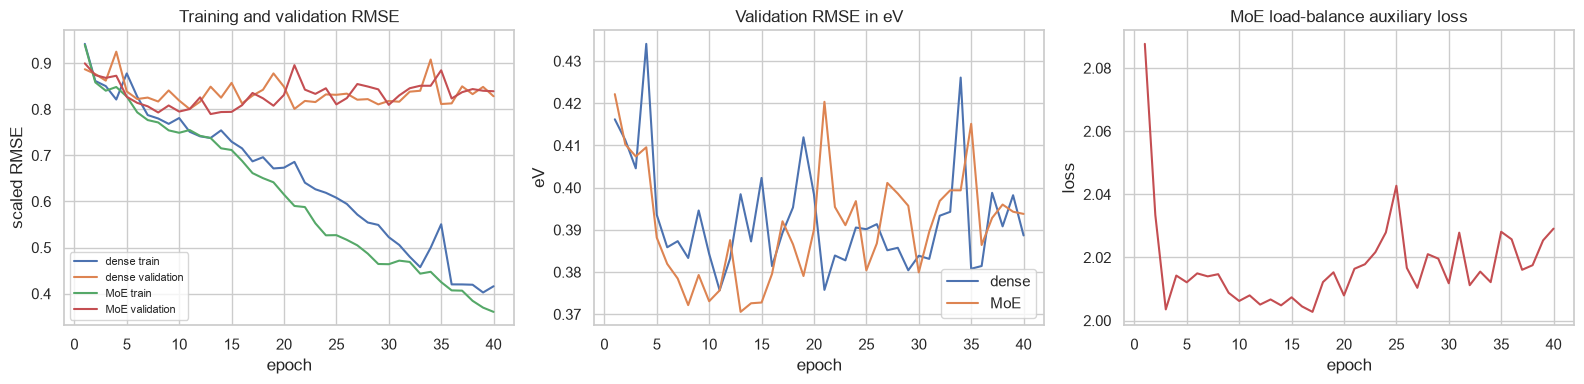

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(dense_history["epoch"], dense_history["train_rmse_scaled"], label="dense train")
axes[0].plot(dense_history["epoch"], dense_history["val_rmse_scaled"], label="dense validation")
axes[0].plot(moe_history["epoch"], moe_history["train_rmse_scaled"], label="MoE train")
axes[0].plot(moe_history["epoch"], moe_history["val_rmse_scaled"], label="MoE validation")
axes[0].set(title="Training and validation RMSE", xlabel="epoch", ylabel="scaled RMSE")
axes[0].legend(fontsize=8)

axes[1].plot(dense_history["epoch"], dense_history["val_rmse_eV"], label="dense")
axes[1].plot(moe_history["epoch"], moe_history["val_rmse_eV"], label="MoE")
axes[1].set(title="Validation RMSE in eV", xlabel="epoch", ylabel="eV")
axes[1].legend()

axes[2].plot(moe_history["epoch"], moe_history["train_aux_loss"], color="#c44e52")
axes[2].set(title="MoE load-balance auxiliary loss", xlabel="epoch", ylabel="loss")
plt.tight_layout()
plt.show()

## 5. Router behavior and expert utilization

Expert utilization is measured on the validation split after loading the best
checkpoint. For top-2 routing, each token contributes two expert assignments.
A balanced router has utilization close to 0.25 for each of the four experts.

Layer 0 utilization: [0.2464 0.2366 0.2439 0.2731]
Layer 0 mean router probability: [0.2415 0.2206 0.2962 0.2418]
Layer 1 utilization: [0.2361 0.2564 0.2366 0.2709]
Layer 1 mean router probability: [0.2397 0.2836 0.2411 0.2357]

Router statistics:
 layer  mean_router_prob_expert_0  mean_router_prob_expert_1  mean_router_prob_expert_2  mean_router_prob_expert_3  utilization_cv  max_min_utilization_ratio  normalized_utilization_entropy  mean_load_balance_loss
     0                     0.2415                     0.2206                     0.2962                     0.2418          0.0554                     1.1547                          0.9989                  1.0009
     1                     0.2397                     0.2836                     0.2411                     0.2357          0.0582                     1.1472                          0.9988                  1.0009


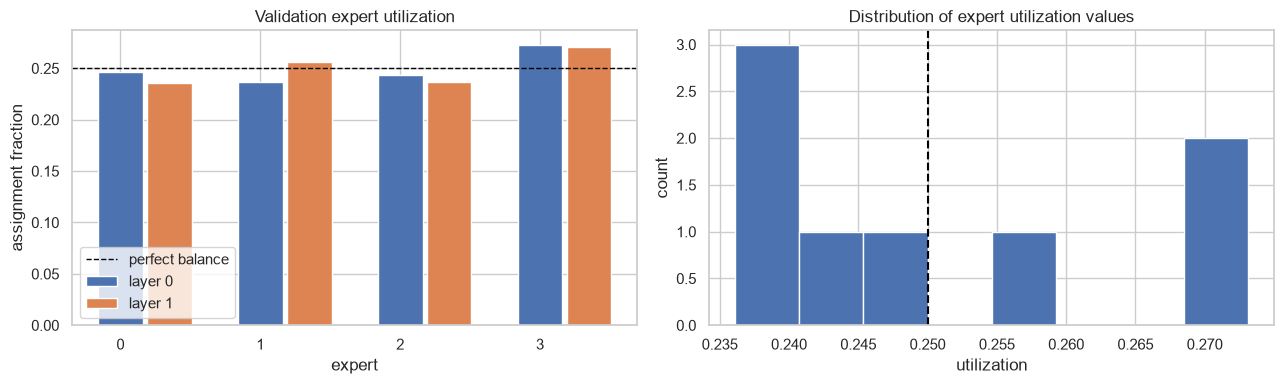

In [13]:
@torch.no_grad()
def collect_router_statistics(model, loader):
    model.eval()
    moe_layers = [module for module in model.modules() if isinstance(module, TopKMoE)]
    aggregates = [
        {
            "router_prob_sum": np.zeros(module.n_experts, dtype=np.float64),
            "assignment_counts": np.zeros(module.n_experts, dtype=np.float64),
            "token_count": 0.0,
            "load_balance_loss": 0.0,
            "batches": 0,
        }
        for module in moe_layers
    ]

    for tokens, _ in loader:
        tokens = tokens.to(DEVICE)
        _, _, _, stats_list = model(tokens, collect_router_stats=True)
        for aggregate, stats in zip(aggregates, stats_list):
            aggregate["router_prob_sum"] += stats["router_prob_sum"]
            aggregate["assignment_counts"] += stats["assignment_counts"]
            aggregate["token_count"] += stats["token_count"]
            aggregate["load_balance_loss"] += stats["load_balance_loss"]
            aggregate["batches"] += 1

    rows = []
    for layer_index, aggregate in enumerate(aggregates):
        utilization = aggregate["assignment_counts"] / aggregate["assignment_counts"].sum()
        mean_router_prob = aggregate["router_prob_sum"] / aggregate["token_count"]
        nonzero = utilization > 0
        entropy = -np.sum(utilization[nonzero] * np.log(utilization[nonzero]))
        normalized_entropy = entropy / np.log(len(utilization))
        rows.append({
            "layer": layer_index,
            "mean_router_prob_expert_0": mean_router_prob[0],
            "mean_router_prob_expert_1": mean_router_prob[1],
            "mean_router_prob_expert_2": mean_router_prob[2],
            "mean_router_prob_expert_3": mean_router_prob[3],
            "utilization_cv": utilization.std(ddof=0) / utilization.mean(),
            "max_min_utilization_ratio": np.inf if utilization.min() == 0 else utilization.max() / utilization.min(),
            "normalized_utilization_entropy": normalized_entropy,
            "mean_load_balance_loss": aggregate["load_balance_loss"] / max(1, aggregate["batches"]),
        })
        print(f"Layer {layer_index} utilization:", np.round(utilization, 4))
        print(f"Layer {layer_index} mean router probability:", np.round(mean_router_prob, 4))
    return pd.DataFrame(rows), aggregates

router_table, router_aggregates = collect_router_statistics(moe_model, val_loader)
print("\nRouter statistics:")
print(router_table.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for layer_index, aggregate in enumerate(router_aggregates):
    utilization = aggregate["assignment_counts"] / aggregate["assignment_counts"].sum()
    axes[0].bar(np.arange(4) + layer_index * 0.35, utilization, width=0.32, label=f"layer {layer_index}")
axes[0].axhline(1 / 4, color="black", linestyle="--", linewidth=1, label="perfect balance")
axes[0].set(title="Validation expert utilization", xlabel="expert", ylabel="assignment fraction")
axes[0].set_xticks(range(4))
axes[0].legend()

all_utilization = np.concatenate([
    aggregate["assignment_counts"] / aggregate["assignment_counts"].sum()
    for aggregate in router_aggregates
])
axes[1].hist(all_utilization, bins=8, color="#4c72b0", edgecolor="white")
axes[1].axvline(0.25, color="black", linestyle="--")
axes[1].set(title="Distribution of expert utilization values", xlabel="utilization", ylabel="count")
plt.tight_layout()
plt.show()

## 6. Final test comparison

The test predictions are produced only after the dense and MoE checkpoints have
been selected using validation RMSE. A linear baseline is included to anchor
the result to the Section 3 workflow.

In [14]:
dense_model = ModernTransformerRegressor(len(vocab), MAX_LEN, use_moe=False).to(DEVICE)
dense_model.load_state_dict(dense_state)
dense_train_pred = inverse_target(predict_scaled(dense_model, train_eval_loader))
dense_val_pred = inverse_target(predict_scaled(dense_model, val_loader))
dense_test_pred = inverse_target(predict_scaled(dense_model, test_loader))
moe_train_pred = inverse_target(predict_scaled(moe_model, train_eval_loader))
moe_val_pred = inverse_target(predict_scaled(moe_model, val_loader))
moe_test_pred = inverse_target(predict_scaled(moe_model, test_loader))

model_metrics = {}
for name, train_pred, val_pred, test_pred in [
    ("dense modern Transformer", dense_train_pred, dense_val_pred, dense_test_pred),
    ("top-2 MoE Transformer", moe_train_pred, moe_val_pred, moe_test_pred),
]:
    model_metrics[name] = pd.DataFrame({
        "train": regression_metrics(y_train_raw, train_pred),
        "validation": regression_metrics(y_val_raw, val_pred),
        "test": regression_metrics(y_test_raw, test_pred),
    }).T

for name, table in model_metrics.items():
    print(name)
    print(table.round(4).to_string())
    print()

honest_features = [
    "Energy_Hatree",
    "es",
    "Isotropic_Polarizability_au",
    "Inner_energy_correction_Hatree",
    "Thermal_correction_to_Enthalpy_Hatree",
    "Thermal_correction_to_Gibbs_Free_Energy_Hatree",
    "Entropy_Hatree",
    "Dipole_Debye",
    "Gibbs_Free_Energy_Hatree",
    "Enthalpy_Hatree",
]

def fit_linear_baseline(feature_frame, train_rows, test_rows):
    model = LinearRegression()
    scaler = StandardScaler()
    x_train = scaler.fit_transform(feature_frame.iloc[train_rows])
    x_test = scaler.transform(feature_frame.iloc[test_rows])
    model.fit(x_train, df.iloc[train_rows][TARGET])
    prediction = model.predict(x_test)
    return regression_metrics(df.iloc[test_rows][TARGET], prediction), prediction

feature_frame = df[honest_features].astype(float)
section3_metrics, section3_pred = fit_linear_baseline(feature_frame, train_val_idx, test_idx)
same_budget_metrics, _ = fit_linear_baseline(feature_frame, train_idx, test_idx)

comparison = pd.DataFrame({
    "test R2": {
        "Dense modern Transformer": model_metrics["dense modern Transformer"].loc["test", "R2"],
        "Top-2 MoE Transformer": model_metrics["top-2 MoE Transformer"].loc["test", "R2"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["R2"],
        "Section 3-style linear baseline, 740-row train budget": section3_metrics["R2"],
    },
    "test MAE": {
        "Dense modern Transformer": model_metrics["dense modern Transformer"].loc["test", "MAE"],
        "Top-2 MoE Transformer": model_metrics["top-2 MoE Transformer"].loc["test", "MAE"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["MAE"],
        "Section 3-style linear baseline, 740-row train budget": section3_metrics["MAE"],
    },
    "test MSE": {
        "Dense modern Transformer": model_metrics["dense modern Transformer"].loc["test", "MSE"],
        "Top-2 MoE Transformer": model_metrics["top-2 MoE Transformer"].loc["test", "MSE"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["MSE"],
        "Section 3-style linear baseline, 740-row train budget": section3_metrics["MSE"],
    },
    "test RMSE": {
        "Dense modern Transformer": model_metrics["dense modern Transformer"].loc["test", "RMSE"],
        "Top-2 MoE Transformer": model_metrics["top-2 MoE Transformer"].loc["test", "RMSE"],
        "Linear baseline, same 555-row train budget": same_budget_metrics["RMSE"],
        "Section 3-style linear baseline, 740-row train budget": section3_metrics["RMSE"],
    },
})
print("Final test comparison:")
print(comparison.round(4).to_string())

resource_table = pd.DataFrame({
    "total parameters": {
        "Dense modern Transformer": parameter_count(dense_model),
        "Top-2 MoE Transformer": parameter_count(moe_model),
    },
    "active parameters per token": {
        "Dense modern Transformer": active_parameter_count(dense_model),
        "Top-2 MoE Transformer": active_parameter_count(moe_model),
    },
    "training seconds": {
        "Dense modern Transformer": dense_seconds,
        "Top-2 MoE Transformer": moe_seconds,
    },
    "process peak RSS MiB": {
        "Dense modern Transformer": dense_memory_mb,
        "Top-2 MoE Transformer": moe_memory_mb,
    },
})
print("\nResource comparison:")
print(resource_table.round(3).to_string())

dense modern Transformer
                R2     MAE     MSE    RMSE
train       0.4614  0.2669  0.1186  0.3444
validation  0.3704  0.2876  0.1411  0.3757
test        0.3263  0.2816  0.1833  0.4281

top-2 MoE Transformer
                R2     MAE     MSE    RMSE
train       0.4886  0.2582  0.1126  0.3356
validation  0.3875  0.2804  0.1373  0.3706
test        0.2977  0.2817  0.1911  0.4371

Final test comparison:
                                                       test R2  test MAE  test MSE  test RMSE
Dense modern Transformer                                0.3263    0.2816    0.1833     0.4281
Top-2 MoE Transformer                                   0.2977    0.2817    0.1911     0.4371
Linear baseline, same 555-row train budget              0.2334    0.3050    0.2086     0.4567
Section 3-style linear baseline, 740-row train budget   0.2494    0.3011    0.2042     0.4519

Resource comparison:
                          total parameters  active parameters per token  training seconds  p

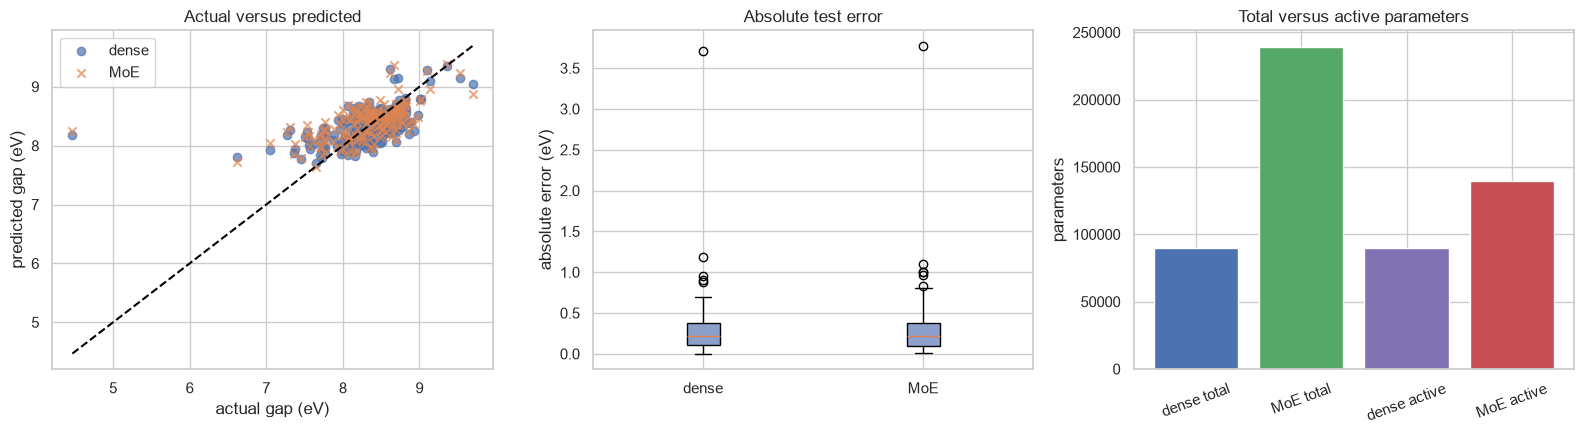

Dense best validation RMSE (eV): 0.3757
MoE best validation RMSE (eV): 0.3706
Dense test RMSE (eV): 0.4281
MoE test RMSE (eV): 0.4371


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test_raw, dense_test_pred, alpha=0.70, label="dense")
axes[0].scatter(y_test_raw, moe_test_pred, alpha=0.70, marker="x", label="MoE")
axis_min = min(y_test_raw.min(), dense_test_pred.min(), moe_test_pred.min())
axis_max = max(y_test_raw.max(), dense_test_pred.max(), moe_test_pred.max())
axes[0].plot([axis_min, axis_max], [axis_min, axis_max], color="black", linestyle="--")
axes[0].set(title="Actual versus predicted", xlabel="actual gap (eV)", ylabel="predicted gap (eV)")
axes[0].legend()

dense_errors = np.abs(y_test_raw - dense_test_pred)
moe_errors = np.abs(y_test_raw - moe_test_pred)
axes[1].boxplot(
    [dense_errors, moe_errors],
    tick_labels=["dense", "MoE"],
    patch_artist=True,
    boxprops={"facecolor": "#8da0cb"},
)
axes[1].set(title="Absolute test error", ylabel="absolute error (eV)")

axes[2].bar(
    ["dense total", "MoE total", "dense active", "MoE active"],
    [
        parameter_count(dense_model),
        parameter_count(moe_model),
        active_parameter_count(dense_model),
        active_parameter_count(moe_model),
    ],
    color=["#4c72b0", "#55a868", "#8172b3", "#c44e52"],
)
axes[2].set(title="Total versus active parameters", ylabel="parameters")
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print("Dense best validation RMSE (eV):", round(dense_history.loc[dense_best_epoch - 1, "val_rmse_eV"], 4))
print("MoE best validation RMSE (eV):", round(moe_history.loc[moe_best_epoch - 1, "val_rmse_eV"], 4))
print("Dense test RMSE (eV):", round(model_metrics["dense modern Transformer"].loc["test", "RMSE"], 4))
print("MoE test RMSE (eV):", round(model_metrics["top-2 MoE Transformer"].loc["test", "RMSE"], 4))

## 7. Critical answers

**1. What modern changes were tested?**

The dense baseline now uses pre-normalized blocks, RMSNorm, RoPE, and a gated
SwiGLU feed-forward network. These changes make the model closer to current
Transformer designs while keeping it small enough to train on CPU. The MoE
variant keeps the same attention stack and replaces each dense SwiGLU layer
with four expert SwiGLU layers and a learned top-2 router.

**2. What did the router learn?**

The router statistics report the mean soft routing probability and the actual
top-2 assignment fraction for each expert. A perfectly balanced four-expert
router would assign about 25% of expert assignments to each expert. The
coefficient of variation, maximum/minimum ratio, and normalized entropy make
imbalance visible. These numbers describe this small dataset only; they are not
evidence that a large MoE system would route chemical motifs in the same way.

**3. How do dense and MoE compare?**

The final table shows validation and test R2, MAE, MSE, and RMSE for both models,
plus a linear baseline with the same training budget and the Section 3-style
linear baseline with more training rows. The MoE model has more total
parameters but fewer active parameters per token than its total parameter
count. If its test error is not better, the likely explanation is that the
dataset is tiny and the routing problem is harder than the extra capacity is
worth.

**4. When is MoE sensible?**

MoE is sensible when many training tokens are available, model capacity is a
constraint, inference compute should stay near a smaller dense model, and
infrastructure can handle routing and communication. It is not sensible when
the dataset is small, experts would be undertrained, interpretability is the
priority, or serving hardware makes sparse routing slower than a dense model.
For a 555-row polymer regression task, MoE is an educational architecture
demonstration rather than an obvious engineering win.

**5. What are the limitations?**

The split is random rather than grouped by polymer family. The target and
numeric features are calculated from the same source. The test set has only 186
rows, so the metric differences are noisy. The router statistics are measured
after validation checkpoint selection and should not be interpreted as causal
chemistry. Memory is reported as sampled process resident memory during each
training run, not an isolated GPU measurement.

## 8. Critical AI review

**Accepted suggestion.** A review suggestion was to make the MoE comparison
fair by reporting both total and active parameter counts. I accepted it because
MoE capacity and per-token compute are different quantities. The notebook now
separates total parameters, active parameters per token, training time, and
process peak memory.

**Rejected suggestion.** Another suggestion was to increase the expert count
until the MoE test R2 exceeded the dense model. I rejected that because it would
turn validation into hidden test-set tuning and would not teach a reliable
architecture comparison. The fixed 4-expert top-2 design is reported as
specified, and the limitations are stated explicitly.